In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import lightgbm as lgb
from nba_api.stats.endpoints import leaguegamelog, playergamelogs, teamgamelogs
from time import sleep
from typing import Dict, Tuple
from tqdm import tqdm
import glob
import math
from datetime import timedelta



In [2]:
pd.options.display.max_columns=50

In [3]:
data_path = Path.cwd().parent / 'data' / 'raw'
print(data_path)
files = glob.glob("c:/Users/jorda/NBA_Projects/nba_model_using_player_embeddings/data/raw/shotdetail*.csv")

df_list = []

for file in files:
    if file[-8:-4] > '2013':
        temp_df = pd.read_csv(file)
        df_list.append(temp_df)

shotdetail_df = pd.concat(df_list, ignore_index=True)


shotdetail_df.info()


c:\Users\jorda\NBA_Projects\nba_model_using_player_embeddings\data\raw
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2227469 entries, 0 to 2227468
Data columns (total 24 columns):
 #   Column               Dtype 
---  ------               ----- 
 0   GRID_TYPE            object
 1   GAME_ID              int64 
 2   GAME_EVENT_ID        int64 
 3   PLAYER_ID            int64 
 4   PLAYER_NAME          object
 5   TEAM_ID              int64 
 6   TEAM_NAME            object
 7   PERIOD               int64 
 8   MINUTES_REMAINING    int64 
 9   SECONDS_REMAINING    int64 
 10  EVENT_TYPE           object
 11  ACTION_TYPE          object
 12  SHOT_TYPE            object
 13  SHOT_ZONE_BASIC      object
 14  SHOT_ZONE_AREA       object
 15  SHOT_ZONE_RANGE      object
 16  SHOT_DISTANCE        int64 
 17  LOC_X                int64 
 18  LOC_Y                int64 
 19  SHOT_ATTEMPTED_FLAG  int64 
 20  SHOT_MADE_FLAG       int64 
 21  GAME_DATE            int64 
 22  HTM                

In [4]:
data_path = Path.cwd().parent / 'data' / 'raw'
print(data_path)
files = glob.glob("c:/Users/jorda/NBA_Projects/nba_model_using_player_embeddings/data/raw/nbastatsv3*.csv")

df_list = []

for file in files:
    if file[-8:-4] > '2013':
        temp_df = pd.read_csv(file)
        if 'po' in file:
            temp_df['isRegularSeason'] = 0
        else:
            temp_df['isRegularSeason'] = 1
        
        temp_df['season'] = file[-8:-4] + '-' + str(int(file[-8:-4]) + 1)[-2:] 
        df_list.append(temp_df)

nbapbp_df = pd.concat(df_list, ignore_index=True)


nbapbp_df.info()


c:\Users\jorda\NBA_Projects\nba_model_using_player_embeddings\data\raw
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6259556 entries, 0 to 6259555
Data columns (total 25 columns):
 #   Column           Dtype  
---  ------           -----  
 0   actionNumber     int64  
 1   clock            object 
 2   period           int64  
 3   teamId           int64  
 4   teamTricode      object 
 5   personId         int64  
 6   playerName       object 
 7   playerNameI      object 
 8   xLegacy          int64  
 9   yLegacy          int64  
 10  shotDistance     int64  
 11  shotResult       object 
 12  isFieldGoal      int64  
 13  scoreHome        float64
 14  scoreAway        float64
 15  pointsTotal      int64  
 16  location         object 
 17  description      object 
 18  actionType       object 
 19  subType          object 
 20  videoAvailable   int64  
 21  actionId         int64  
 22  gameId           int64  
 23  isRegularSeason  int64  
 24  season           object 
dtypes

In [5]:
df = pd.merge(nbapbp_df, shotdetail_df, how='left', left_on=['gameId', 'personId', 'actionNumber'], right_on = ['GAME_ID', 'PLAYER_ID', 'GAME_EVENT_ID'])

df['time'] = df['clock'].str[2:4] 

del nbapbp_df   
del shotdetail_df   


In [6]:
# full_df.loc[full_df['isFieldGoal']==1, ['playerName', 'PLAYER_NAME', 'actionType', 'ACTION_TYPE', 'shotDistance', 'SHOT_DISTANCE', 'SHOT_ZONE_AREA', 'description']]
df = df[['actionNumber', 'clock', 'period', 'teamId', 'teamTricode', 'personId',
       'playerName', 'playerNameI', 'xLegacy', 'yLegacy', 'shotDistance',
       'shotResult', 'isFieldGoal', 'scoreHome', 'scoreAway', 'pointsTotal',
       'location', 'description', 'actionType', 'subType', 'videoAvailable',
       'actionId', 'gameId', 'isRegularSeason', 'season',
       'SHOT_TYPE', 'SHOT_ZONE_BASIC', 'SHOT_ZONE_AREA', 'SHOT_ZONE_RANGE', 'SHOT_DISTANCE',
       'LOC_X', 'LOC_Y', 'SHOT_MADE_FLAG']].copy()



In [7]:
# full_df.loc[(full_df['xLegacy'] != full_df['LOC_X']) & (full_df['LOC_X'].notnull()) & (full_df['isFieldGoal'] == 1), ['season', 'gameId', 'xLegacy', 'yLegacy',
#  'LOC_X', 'LOC_Y', 'description', 'SHOT_ZONE_AREA', 'SHOT_ZONE_RANGE', 'shotDistance', 'SHOT_DISTANCE']]


# full_df.loc[(abs(full_df['xLegacy']) == 223)]

# full_df.loc[(full_df['shotDistance'] == 0) & (full_df['isFieldGoal']==1)]
df['shotDistanceFixed'] = df['shotDistance'].copy()
df.loc[(df['SHOT_TYPE'] == '3PT Field Goal') & (df['shotDistance'] < 22), 'shotDistanceFixed'] = df['SHOT_DISTANCE'] 

In [8]:
df.loc[df['description'].isnull()]

df['description'] = df['description'].fillna('Jump Ball')

In [9]:
display(df['SHOT_ZONE_BASIC'].value_counts())
df['SHOT_ZONE_AREA'].value_counts()


SHOT_ZONE_BASIC
Restricted Area          691451
Above the Break 3        591549
Mid-Range                376350
In The Paint (Non-RA)    373033
Left Corner 3             98667
Right Corner 3            91543
Backcourt                  4723
Name: count, dtype: int64

SHOT_ZONE_AREA
Center(C)                1252023
Left Side Center(LC)      280317
Right Side Center(RC)     272827
Left Side(L)              212688
Right Side(R)             204232
Back Court(BC)              5229
Name: count, dtype: int64

In [10]:
import numpy as np
import pandas as pd

# 1. SETUP & SORTING
# Ensure we are working on a copy and sorted chronologically
df = df.sort_values(by=['gameId', 'period', 'actionNumber']).reset_index(drop=True)
df['actionType'] = df['actionType'].str.strip()

# 2. MAP TO NUMERIC CODES
# We create a new column 'actionCode' to store the standard integer values
# 1: Made Shot, 2: Missed Shot, 4: Rebound, 5: Turnover
action_map = {
    'Made Shot': 1,
    'Missed Shot': 2,
    'Rebound': 4,
    'Turnover': 5
    # We leave out Free Throws/Fouls/etc. as they don't trigger the specific 
    # "Shot Quality" logic, but they will just result in NaN (which is fine)
}

df['actionCode'] = df['actionType'].map(action_map)

# Verify the mapping worked
display(df[['actionType', 'actionCode']].value_counts().head(10))


actionType   actionCode
Rebound      4.0           1333704
Missed Shot  2.0           1200450
Made Shot    1.0           1027415
Turnover     5.0            359283
Name: count, dtype: int64

In [11]:
import pandas as pd
import numpy as np

# --- 1. SETUP ZONES & CONTEXT ---
zone_map = {
    'Restricted Area': 'Rim',
    'Left Corner 3': 'Corner3',
    'Right Corner 3': 'Corner3',
    'Above the Break 3': 'Arc3',
    'Mid-Range': 'LongMidRange',
    'In The Paint (Non-RA)': 'ShortMidRange',
    'Backcourt': 'BackCourt'
}
df['ShotZone'] = df['SHOT_ZONE_BASIC'].map(zone_map)
df['description'] = df['description'].fillna('Jump Ball')

# 1a. Flag Block Events
# We check if the row ITSELF is a block event
df['is_block_event'] = df['description'].str.contains('BLOCK', case=False, na=False)

# 1b. Vectorized Forward Fill for Shot Context (The Memory Error Fix)
# We track the Zone and Team of the last shot (Make/Miss) across all subsequent rows
# until a new shot happens.
mask_shot = df['actionCode'].isin([1, 2])

df['LatestShotZone'] = df['ShotZone'].where(mask_shot).ffill()
df['LatestShooterTeam'] = df['teamId'].where(mask_shot).ffill()

# --- 2. POSSESSION START LOGIC (Mostly Unchanged) ---
df['prev_actionCode'] = df.groupby('gameId')['actionCode'].shift(1)
df['prev_teamId'] = df.groupby('gameId')['teamId'].shift(1)


conditions = [
    # 1. Opponent Made Shot
    (df['prev_actionCode'] == 1) & (df['teamId'] != df['prev_teamId']),
    # 2. Opponent Turnover
    (df['prev_actionCode'] == 5) & (df['teamId'] != df['prev_teamId']),
    # 3. Defensive Rebound 
    (df['actionCode'] == 4) & (df['prev_actionCode'] == 2) & (df['teamId'] != df['prev_teamId']),
    # 4. Period Change
    (df['period'] != df.groupby('gameId')['period'].shift(1))
]
choices = ['OffMake', 'OffTurnover', 'OffMiss', 'OffDeadball']

df['EventStartType'] = np.select(conditions, choices, default=None) # Use NaN default for ffill
df['StartType'] = df.groupby('gameId')['EventStartType'].ffill().fillna('OffDeadball')

# --- 3. ROBUST OFFENSIVE REBOUND CONTEXT ---

# 3a. Identify OREBs reliably
# An OREB is a Rebound (4) by the SAME TEAM that took the last shot.
# This works even if a "Block" event row sits between the Shot and the Rebound.
is_oreb = (df['actionCode'] == 4) & (df['teamId'] == df['LatestShooterTeam'])

# 3b. Determine the Shot Type that led to the OREB
# Check if the PREVIOUS row was a block event
df['prev_was_block'] = df['is_block_event'].shift(1).fillna(False)

# Logic for OrebShotType:
# 1. If previous row was a Block -> LatestShotZone + "Blocked"
# 2. Else -> LatestShotZone (Standard Miss)
# (Note: You can add an extra check here if standard misses sometimes have "BLOCK" in text)

# 3. Create "Previous Event" Helper Columns
df['prev_ShotZone'] = df.groupby('gameId')['ShotZone'].shift(1)

# A. Define Logic Conditions
# 1. Opponent Made Shot
cond_off_make = (df['prev_actionCode'] == 1) & (df['teamId'] != df['prev_teamId'])

# 2. Opponent Missed Shot (Defensive Rebound)
cond_def_reb = (df['actionCode'] == 4) & (df['teamId'] != df['prev_teamId']) & (df['prev_actionCode'] == 2)

# B. Construct the Strings
# default StartType
df['EventStartType'] = None

# Logic for Makes: "Off" + Zone + "Make"
df.loc[cond_off_make, 'EventStartType'] = 'Off' + df.loc[cond_off_make, 'prev_ShotZone'] + 'Make'

# Logic for Misses vs Blocks
# If it was a Def Reb, we check if it was blocked
is_blocked_miss = (cond_def_reb) & (df['prev_was_block'])
is_clean_miss = (cond_def_reb) & (~df['prev_was_block'])

df.loc[is_blocked_miss, 'EventStartType'] = 'Off' + df.loc[is_blocked_miss, 'prev_ShotZone'] + 'Block'
df.loc[is_clean_miss, 'EventStartType'] = 'Off' + df.loc[is_clean_miss, 'prev_ShotZone'] + 'Miss'

# Logic for Turnovers
cond_turnover = (df['prev_actionCode'] == 5) & (df['teamId'] != df['prev_teamId'])
df.loc[cond_turnover, 'EventStartType'] = 'OffTurnover'

# C. Forward Fill StartType
df['StartType'] = df.groupby('gameId')['EventStartType'].ffill().fillna('OffDeadball')


# 1. Identify Orebs (Rebound by same team as shooter)
is_oreb = (df['actionCode'] == 4) & (df['teamId'] == df['LatestShooterTeam'])

# 2. Determine Oreb Context (Blocked or Standard)
cond_blocked_oreb = (is_oreb) & (df['prev_was_block'])
cond_standard_oreb = (is_oreb) & (~df['prev_was_block'])

df['OrebShotType'] = np.nan
df.loc[cond_blocked_oreb, 'OrebShotType'] = df.loc[cond_blocked_oreb, 'LatestShotZone'] + 'Blocked'
df.loc[cond_standard_oreb, 'OrebShotType'] = df.loc[cond_standard_oreb, 'LatestShotZone']

# 3. Forward Fill Oreb Context
df['PossessionID'] = df['EventStartType'].notna().cumsum()
df['OrebShotType'] = df.groupby('PossessionID')['OrebShotType'].ffill()

# 4. Final PlayStartType Function
def get_play_start_type_v2(row):
    if pd.isna(row['OrebShotType']):
        return row['StartType']
    
    ost = str(row['OrebShotType'])
    
    # Handle the specific "3pt Oreb" combinations requested
    if ost in ['Arc3Blocked', 'Corner3Blocked']:
        return 'Off3BlockedOreb'
    elif ost in ['Corner3', 'Arc3']:
        return 'Off3Oreb'
    else:
        # Returns OffAtRimOreb, OffLongMidRangeBlockedOreb, etc.
        return 'Off' + ost + 'Oreb'

df['PlayStartType'] = df.apply(get_play_start_type_v2, axis=1)


# Check results
cols = ['gameId', 'actionType', 'description', 'StartType', 'OrebShotType', 'PlayStartType']
print(df[cols].head(20))

C:\Users\jorda\AppData\Local\Temp\ipykernel_109420\4004089231.py:58: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['prev_was_block'] = df['is_block_event'].shift(1).fillna(False)
C:\Users\jorda\AppData\Local\Temp\ipykernel_109420\4004089231.py:106: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['RimBlocked' 'ShortMidRangeBlocked' 'LongMidRangeBlocked' ...
 'RimBlocked' 'RimBlocked' 'RimBlocked']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[cond_blocked_oreb, 'OrebShotType'] = df.loc[cond_blocked_oreb, 'LatestShotZone'] + 'Blocked'


      gameId   actionType                                        description  \
0   21400001       period                  Start of 1st Period (8:13 PM EST)   
1   21400001    Jump Ball        Jump Ball Davis vs. Vucevic: Tip to Holiday   
2   21400001  Missed Shot                           MISS Davis 20' Jump Shot   
3   21400001      Rebound                     Fournier REBOUND (Off:0 Def:1)   
4   21400001    Made Shot  Vucevic 19' Jump Bank Shot (2 PTS) (Payton 1 AST)   
5   21400001     Turnover                  Holiday Bad Pass Turnover (P1.T1)   
6   21400001          NaN                              O'Quinn STEAL (1 STL)   
7   21400001     Turnover                Fournier Traveling Turnover (P1.T1)   
8   21400001  Missed Shot                           MISS Davis 18' Jump Shot   
9   21400001      Rebound                      Vucevic REBOUND (Off:0 Def:1)   
10  21400001  Missed Shot                               MISS Payton 2' Layup   
11  21400001          NaN               

In [12]:
# df['OrebShotType'].value_counts()
df['PlayStartType'].value_counts()





PlayStartType
OffArc3Miss                    989298
OffTurnover                    880594
OffRimMake                     828128
OffLongMidRangeMiss            551005
OffShortMidRangeMiss           416095
OffRimMiss                     369273
OffArc3Make                    344649
Off3Oreb                       303220
OffCorner3Miss                 291722
OffShortMidRangeMake           273760
OffRimOreb                     246229
OffLongMidRangeMake            239717
OffShortMidRangeOreb           142301
OffLongMidRangeOreb            121662
OffCorner3Make                 121660
OffRimBlockedOreb               48646
OffDeadball                     39375
OffShortMidRangeBlockedOreb     24910
OffBackCourtMiss                18644
OffLongMidRangeBlockedOreb       4504
Off3BlockedOreb                  3477
OffBackCourtMake                  503
OffBackCourtOreb                  179
OffBackCourtBlockedOreb             5
Name: count, dtype: int64

In [13]:
raw_angle = np.abs(np.degrees(np.arctan2(df['xLegacy'], df['yLegacy'])))  
df['shotAngle'] = np.where(raw_angle < 90, raw_angle, 180 - raw_angle)
df['shotAngle'] = df['shotAngle'].round(1)

df.head()

,actionNumber,clock,period,teamId,teamTricode,personId,playerName,playerNameI,xLegacy,yLegacy,shotDistance,shotResult,isFieldGoal,scoreHome,scoreAway,pointsTotal,location,description,actionType,subType,videoAvailable,actionId,gameId,isRegularSeason,season,SHOT_TYPE,SHOT_ZONE_BASIC,SHOT_ZONE_AREA,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_MADE_FLAG,shotDistanceFixed,actionCode,ShotZone,is_block_event,LatestShotZone,LatestShooterTeam,prev_actionCode,prev_teamId,EventStartType,StartType,prev_was_block,prev_ShotZone,OrebShotType,PossessionID,PlayStartType,shotAngle
0,0,PT12M00.00S,1,0,NaN,0,NaN,NaN,0,0,0,NaN,0,0.0,0.0,0,NaN,Start of 1st Period (8:13 PM EST),period,start,0,1,21400001,1,2014-15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,False,NaN,NaN,NaN,NaN,None,OffDeadball,False,NaN,NaN,0,OffDeadball,0.0
1,1,PT12M00.00S,1,1610612740,NOP,203076,Davis,A. Davis,0,0,0,NaN,0,NaN,NaN,0,h,Jump Ball Davis vs. Vucevic: Tip to Holiday,Jump Ball,NaN,1,2,21400001,1,2014-15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,False,NaN,NaN,NaN,0.000000e+00,None,OffDeadball,False,NaN,NaN,0,OffDeadball,0.0
2,2,PT11M43.00S,1,1610612740,NOP,203076,Davis,A. Davis,50,194,20,Missed,1,NaN,NaN,0,h,MISS Davis 20' Jump Shot,Missed Shot,Jump Shot,1,3,21400001,1,2014-15,2PT Field Goal,Mid-Range,Center(C),16-24 ft.,20.0,50.0,194.0,0.0,20,2.0,LongMidRange,False,LongMidRange,1.610613e+09,NaN,1.610613e+09,None,OffDeadball,False,NaN,NaN,0,OffDeadball,14.5
3,3,PT11M42.00S,1,1610612753,ORL,203095,Fournier,E. Fournier,0,0,0,NaN,0,NaN,NaN,0,v,Fournier REBOUND (Off:0 Def:1),Rebound,Unknown,1,4,21400001,1,2014-15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,4.0,NaN,False,LongMidRange,1.610613e+09,2.0,1.610613e+09,OffLongMidRangeMiss,OffLongMidRangeMiss,False,LongMidRange,NaN,1,OffLongMidRangeMiss,0.0
4,4,PT11M31.00S,1,1610612753,ORL,202696,Vucevic,N. Vucevic,-8,189,19,Made,1,0.0,2.0,2,v,Vucevic 19' Jump Bank Shot (2 PTS) (Payton 1 AST),Made Shot,Jump Bank Shot,1,5,21400001,1,2014-15,2PT Field Goal,Mid-Range,Center(C),16-24 ft.,18.0,-8.0,189.0,1.0,19,1.0,LongMidRange,False,LongMidRange,1.610613e+09,4.0,1.610613e+09,None,OffLongMidRangeMiss,False,NaN,NaN,1,OffLongMidRangeMiss,2.4


In [14]:
df['period'] = np.where(df['period']>5, 5, df['period'])

In [15]:
df['shotResult'].unique()

array([nan, 'Missed', 'Made'], dtype=object)

In [16]:
df.loc[df['description'].str.contains('put', case=False)]

df['putback'] = df['description'].str.contains('putback', case=False) 
df['home'] = (df['location']=='h').astype(int)
df['3PT'] = (df['SHOT_TYPE'] == '3PT Field Goal').astype(int)
df['shotResult'] = (df['shotResult'] == 'Made').astype(int)

df['points_on_shot'] = df['shotResult'] * np.where(df['3PT'] == 1, 3, 2)
df['pre_shot_score_home'] = df['scoreHome'] - np.where(df['home'], df['points_on_shot'], 0)
df['pre_shot_score_away'] = df['scoreAway'] - np.where(~df['home'], df['points_on_shot'], 0)

df['startScoreDifferential'] = np.where(
        df['home'], 
        df['pre_shot_score_home'] - df['pre_shot_score_away'], 
        df['pre_shot_score_away'] - df['pre_shot_score_home']
    )

cols = ['season', 'ShotZone', 'OrebShotType', 'PlayStartType']
       


# print(df.loc[df['isFieldGoal'] == 1, 'subType'].unique())

In [17]:
df['shotResult'].value_counts()

shotResult
0    5232141
1    1027415
Name: count, dtype: int64

In [18]:
df_final = df.loc[df['isFieldGoal']==1]
df_final = pd.get_dummies(df_final, columns=cols, prefix='is')

display(df_final['shotResult'].value_counts())

shotResult
0    1200449
1    1027415
Name: count, dtype: int64

In [19]:
# 1. Combine Off Block Orebs
cols_block_orebs = [
    'is_Off3BlockedOreb', 
    'is_OffRimBlockedOreb', 
    'is_OffLongMidRangeBlockedOreb', 
    'is_OffShortMidRangeBlockedOreb'
]
df_final['combined_off_block_orebs'] = (df_final[cols_block_orebs].sum(axis=1) == 1).astype(int)


# 3. Combine Off Makes
cols_off_makes = [
    'is_OffArc3Make', 
    'is_OffCorner3Make', 
    'is_OffRimMake', 
    'is_OffLongMidRangeMake', 
    'is_OffShortMidRangeMake'
]
df_final['combined_off_makes'] = (df_final[cols_off_makes].sum(axis=1) == 1).astype(int)

# 4. Combine Off Orebs
cols_off_orebs = [
    'is_Off3Oreb', 
    'is_OffRimOreb', 
    'is_OffLongMidRangeOreb', 
    'is_OffShortMidRangeOreb'
]
df_final['combined_off_orebs'] = (df_final[cols_off_orebs].sum(axis=1) == 1).astype(int)

# 5. Combine Off Missed FG
cols_off_miss = [
    'is_OffArc3Miss', 
    'is_OffCorner3Miss', 
    'is_OffRimMiss', 
    'is_OffLongMidRangeMiss', 
    'is_OffShortMidRangeMiss'
]
df_final['combined_off_missed_fg'] = (df_final[cols_off_miss].sum(axis=1) == 1).astype(int)

In [20]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.metrics import log_loss

# ---------------------------------------------------------
# 1. PREPROCESSING & CLEANING
# ---------------------------------------------------------
def prepare_data(df):
    """
    Cleans raw shot data, removes leakage, and sets up timeline.
    """
    df = df.copy()
    df = df.loc[:, ~df.columns.duplicated()]
    # A. Recover 'Season' Integer from One-Hot Columns (Critical for Time-Series Loop)
    # We map 'is_2014-15' -> 2015, etc.
    season_cols = [c for c in df.columns if 'is_20' in c and '-' in c]
    df['season_end'] = 0
    for col in season_cols:
        # Extract year: "is_2014-15" -> 2015
        year_end = int(col.split('-')[1]) + 2000 
        df.loc[df[col] == 1, 'season_end'] = year_end
        
    # B. Define Target
    target = 'shotResult'
    
    # C. Feature Selection (STRICT NO LEAKAGE)
    # We ONLY include what is known at the moment the ball leaves the hand.
    feature_cols = [
        # Physics / Spatial
        'shotDistanceFixed', 'shotAngle', 
        # Zones (Categorical Flags)
        'is_Arc3', 'is_Corner3', 'is_Rim', 'is_ShortMidRange', 'is_LongMidRange', 'is_BackCourt',
        # Context
        # 'startScoreDifferential'
         'putback', 'isRegularSeason', 'home', '3PT',
        'is_Off3BlockedOreb',
       'is_Off3Oreb', 'is_OffArc3Make', 'is_OffArc3Miss',
       'is_OffBackCourtBlockedOreb', 'is_OffBackCourtMake',
       'is_OffBackCourtMiss', 'is_OffBackCourtOreb', 'is_OffCorner3Make',
       'is_OffCorner3Miss', 'is_OffDeadball', 'is_OffLongMidRangeBlockedOreb',
       'is_OffLongMidRangeMake', 'is_OffLongMidRangeMiss',
       'is_OffLongMidRangeOreb', 'is_OffRimBlockedOreb', 'is_OffRimMake',
       'is_OffRimMiss', 'is_OffRimOreb', 'is_OffShortMidRangeBlockedOreb',
       'is_OffShortMidRangeMake', 'is_OffShortMidRangeMiss',
       'is_OffShortMidRangeOreb', 'is_OffTurnover'
    ]
    
    # D. Drop rows where season wasn't parsed or target is missing
    df = df[df['season_end'] > 0].copy()
    df = df.dropna(subset=[target] + feature_cols)
    
    return df, feature_cols, target

# usage: df_clean, features, target = prepare_data(raw_df)

In [21]:
# ---------------------------------------------------------
# 2. HYPERPARAMETER TUNING FUNCTION
# ---------------------------------------------------------
def tune_xgboost(X_train, y_train, X_val, y_val):
    """
    Tunes XGBoost using the specific validation set (Time-Series safe).
    Uses RandomizedSearch for efficiency.
    """
    # Create a PredefinedSplit so GridSearch uses our explicit Train/Val split
    # -1 indicates training sample, 0 indicates validation sample
    split_index = [-1]*len(X_train) + [0]*len(X_val)
    pds = PredefinedSplit(test_fold=split_index)
    
    # Combine for the search object
    X_combined = pd.concat([X_train, X_val], axis=0)
    y_combined = pd.concat([y_train, y_val], axis=0)
    
    # Define Parameter Grid
    param_grid = {
        'max_depth': [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1],
        'n_estimators': [100, 300, 500],
        'subsample': [0.7, 0.8, 1.0],
        'colsample_bytree': [0.7, 0.8, 1.0],
        'gamma': [0, 0.1, 0.5] # Regularization for "cliffs"
    }
    
    xgb_model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', tree_method='hist')
    
    search = RandomizedSearchCV(
        xgb_model, 
        param_grid, 
        n_iter=10, # Keep low for demo speed, increase to 50 for production
        cv=pds, 
        scoring='neg_log_loss', 
        n_jobs=-1,
        verbose=0
    )
    
    search.fit(X_combined, y_combined)
    return search.best_estimator_, search.best_params_

# ---------------------------------------------------------
# 3. EXPANDING WINDOW BACKTEST (Simulate History)
# ---------------------------------------------------------
def run_expanding_window(df, features, target):
    seasons = sorted(df['season_end'].unique())
    
    # Start predicting from the 3rd available season
    # (Need Season 1 for Train, Season 2 for Tune)
    start_test_idx = 8 
    
    all_predictions = []
    
    print(f"Data spans {seasons[0]} to {seasons[-1]}")
    print(f"Starting predictions at season: {seasons[start_test_idx]}")
    
    # We maintain one persistent 'best_params' dictionary
    # We only re-tune if performance drops, or just re-tune every year (safest)
    
    for i in range(start_test_idx, len(seasons)):
        test_season = seasons[i]
        validation_season = seasons[i-1]
        
        print(f"\n--- Training for Target Season: {test_season} ---")
        
        # 1. Define Timeline Splits
        # TRAIN: Everything up to validation season (History)
        train_mask = df['season_end'] < validation_season
        # VALIDATE: The most recent completed season (Recent Context)
        val_mask = df['season_end'] == validation_season
        # TEST: The target season (Future)
        test_mask = df['season_end'] == test_season
        
        X_train = df.loc[train_mask, features]
        y_train = df.loc[train_mask, target]
        X_val = df.loc[val_mask, features]
        y_val = df.loc[val_mask, target]
        X_test = df.loc[test_mask, features]
        
        print(f"   Train Size: {len(X_train):,} | Val Size: {len(X_val):,}")
        
        # 2. Tune & Train
        # We tune on the Validation set (Recent History) to find params that fit current NBA style
        best_model, params = tune_xgboost(X_train, y_train, X_val, y_val)
        print(f"   Best Params: Depth={params['max_depth']}, LR={params['learning_rate']}")
        
        # 3. Predict on Holdout (Test Season)
        probs = best_model.predict_proba(X_test)[:, 1]
        
        # 4. Store Results
        cols_to_keep = ['season_end', target, 'personId', 'gameId', 'teamId']
        existing_cols = [c for c in cols_to_keep if c in df.columns]


        # Keep original index to allow joining back to Player names/dates later
        chunk = df.loc[test_mask, existing_cols].copy()
        chunk['xFG'] = probs
        chunk['residual'] = chunk[target] - chunk['xFG']
        
        all_predictions.append(chunk)

    return pd.concat(all_predictions), best_model

# Usage:
# final_df = run_expanding_window(df_clean, features, target)
# ---------------------------------------------------------
# 4. EXECUTION
# ---------------------------------------------------------
# Assuming 'df' is your loaded dataframe
df_clean, features, target = prepare_data(df_final)


In [22]:
final_results, best_model = run_expanding_window(df_clean, features, target)

print(final_results.head())



Data spans 2015 to 2024
Starting predictions at season: 2023

--- Training for Target Season: 2023 ---
   Train Size: 1,532,159 | Val Size: 231,293
   Best Params: Depth=8, LR=0.1

--- Training for Target Season: 2024 ---
   Train Size: 1,763,452 | Val Size: 231,870
   Best Params: Depth=6, LR=0.05
         season_end  shotResult  personId    gameId      teamId       xFG  \
4654565        2023           0    203954  22200001  1610612755  0.395594   
4654569        2023           1    203935  22200001  1610612738  0.399109   
4654570        2023           0    202699  22200001  1610612755  0.424426   
4654572        2023           1    202699  22200001  1610612755  0.614173   
4654573        2023           1   1628369  22200001  1610612738  0.388901   

         residual  
4654565 -0.395594  
4654569  0.600891  
4654570 -0.424426  
4654572  0.385827  
4654573  0.611099  


                    Feature  Importance
4                    is_Rim    0.484382
0         shotDistanceFixed    0.149505
7              is_BackCourt    0.097349
11                      3PT    0.050930
34  is_OffShortMidRangeOreb    0.026602
35           is_OffTurnover    0.025351
30            is_OffRimOreb    0.024437
2                   is_Arc3    0.022050
26   is_OffLongMidRangeOreb    0.015071
8                   putback    0.014054


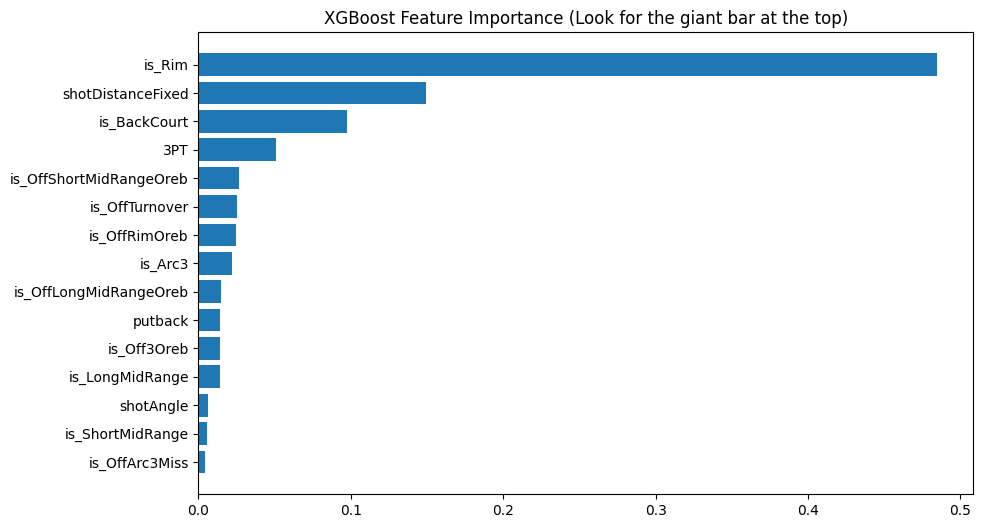

In [47]:
import matplotlib.pyplot as plt

# Get the feature importance dict from the model
# (Assuming 'best_model' is the last trained model from your loop)
importance = best_model.feature_importances_
feature_names = features # The list of columns you used

# Create a DataFrame for easy viewing
fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

# Print the top 10 "Criminals"
print(fi_df.head(10))

# Plot it
plt.figure(figsize=(10, 6))
plt.barh(fi_df['Feature'].head(15), fi_df['Importance'].head(15))
plt.gca().invert_yaxis()
plt.title("XGBoost Feature Importance (Look for the giant bar at the top)")
plt.show()

In [48]:
final_results['xFG'].describe()
# final_results.head()

count    464412.000000
mean          0.446742
std           0.125931
min           0.002824
25%           0.361822
50%           0.400189
75%           0.464379
max           0.926718
Name: xFG, dtype: float64

In [49]:
final_results

,season_end,shotResult,personId,gameId,teamId,xFG,residual
4654565,2023,0,203954,22200001,1610612755,0.395594,-0.395594
4654569,2023,1,203935,22200001,1610612738,0.399109,0.600891
4654570,2023,0,202699,22200001,1610612755,0.424426,-0.424426
4654572,2023,1,202699,22200001,1610612755,0.614173,0.385827
4654573,2023,1,1628369,22200001,1610612738,0.388901,0.611099
...,...,...,...,...,...,...,...
6259540,2024,0,1628369,42300405,1610612738,0.346356,-0.346356
6259545,2024,1,1630702,42300405,1610612742,0.402447,0.597553
6259546,2024,0,1628401,42300405,1610612738,0.395622,-0.395622
6259551,2024,0,1630702,42300405,1610612742,0.632334,-0.632334


In [50]:
def calculate_rolling_player_stats(shot_df):
    """
    Turns shot-level residuals into a player-level daily rating.
    """
    # 1. Sort by Date is crucial for rolling calculations
    # Ensure you have a 'gameDate' or 'date' column in datetime format
    df = shot_df.sort_values(['personId', 'gameId']).copy()
    
    # 2. Define the 'Span' (How quickly does the rating react?)
    # span=1000 shots is roughly ~50-80 games (a full season of "memory")
    # span=300 shots is roughly ~15-20 games (captures "Hot Streaks")
    # A Sharp Model often uses TWO features: Long-Term (Talent) and Short-Term (Form)
    
    # Metric A: Long-Term Talent (Stable)
    df['skill_long_term'] = (
        df.groupby('personId')['residual']
        .transform(lambda x: x.ewm(span=450, min_periods=20).mean())
    )
    
    # Metric B: Short-Term Form (Hot/Cold)
    df['skill_short_term'] = (
        df.groupby('personId')['residual']
        .transform(lambda x: x.ewm(span=90, min_periods=20).mean())
    )
    
    # 3. Aggregation to GAME Level
    # Currently, we have one row per SHOT. We need one row per PLAYER-GAME.
    # We take the *last* value of the previous game to be the "Entering Rating" for the new game.
    
    # Group by Player/Game to get the final residual of the day
    # But wait! We need the rating *before* the game starts.
    # So we simply Shift the shot-level metric by 1 row, then take the first shot of the game.
    
    df['entering_skill_long'] = df.groupby('personId')['skill_long_term'].shift(1)
    df['entering_skill_short'] = df.groupby('personId')['skill_short_term'].shift(1)
    
    # Now drop duplicates to get one row per Player-Game
    player_daily_features = df.drop_duplicates(subset=['personId', 'gameId'], keep='first')
    
    return player_daily_features[['personId', 'gameId', 'entering_skill_long', 'entering_skill_short']]

# Usage
player_features = calculate_rolling_player_stats(final_results)

In [51]:
player_features

,personId,gameId,entering_skill_long,entering_skill_short
4655056,2544,22200002,NaN,NaN
4662326,2544,22200016,-0.034328,-0.013867
4673086,2544,22200037,-0.012503,-0.000659
4686867,2544,22200064,0.021779,0.043075
4692713,2544,22200076,-0.003841,-0.010961
...,...,...,...,...
5797775,1642013,22301108,NaN,NaN
5816201,1642013,22301146,NaN,NaN
5822817,1642013,22301160,NaN,NaN
5830467,1642013,22301176,-0.296111,-0.291371


In [52]:
DB_PATH = Path.cwd().parent / 'data' / 'nba_stats.db'
conn = sqlite3.connect(DB_PATH)

team_df = pd.read_sql("""select * from team_basic_stats tb
                    join team_advanced_stats_v3 ta on tb.TEAM_ID = ta.teamId and tb.GAME_ID = ta.gameId
                    """, con=conn)

team_df

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,...,teamSlug,minutes,estimatedOffensiveRating,offensiveRating,estimatedDefensiveRating,defensiveRating,estimatedNetRating,netRating,assistPercentage,assistToTurnover,assistRatio,offensiveReboundPercentage,defensiveReboundPercentage,reboundPercentage,estimatedTeamTurnoverPercentage,turnoverRatio,effectiveFieldGoalPercentage,trueShootingPercentage,usagePercentage,estimatedUsagePercentage,estimatedPace,pace,pacePer40,possessions,PIE
0,22013,1610612747,LAL,Los Angeles Lakers,0021300003,2013-10-29,LAL vs. LAC,W,240,42,93,0.452,14,29,0.483,18,28,0.643,18,34,52,23,8,6,19,...,lakers,240:00,585.9,117.2,525.5,105.1,60.3,12.1,0.548,1.21,15.8,0.439,0.745,0.577,19.192,19.2,0.527,0.551,1.0,0.984,19.7,98.5,82.08,99.0,0.503
1,22013,1610612748,MIA,Miami Heat,0021300002,2013-10-29,MIA vs. CHI,W,240,37,72,0.514,11,20,0.550,22,29,0.759,5,35,40,26,10,7,20,...,heat,240:00,540.4,108.1,484.7,96.9,55.7,11.1,0.703,1.30,19.5,0.000,0.706,0.000,20.202,20.2,0.590,0.631,1.0,0.963,19.7,98.5,82.08,99.0,0.599
2,22013,1610612753,ORL,Orlando Magic,0021300001,2013-10-29,ORL @ IND,L,240,36,93,0.387,9,19,0.474,6,10,0.600,13,26,39,17,10,6,19,...,magic,240:00,462.8,92.6,516.0,103.2,-53.2,-10.6,0.472,0.89,12.9,0.383,0.683,0.505,20.213,20.2,0.435,0.447,1.0,0.983,18.8,94.0,78.33,94.0,0.339
3,22013,1610612754,IND,Indiana Pacers,0021300001,2013-10-29,IND vs. ORL,W,240,34,71,0.479,7,17,0.412,22,32,0.688,10,34,44,17,4,18,21,...,pacers,240:00,516.0,103.2,462.8,92.6,53.2,10.6,0.500,0.81,13.7,0.317,0.617,0.495,22.340,22.3,0.528,0.570,1.0,0.981,18.8,94.0,78.33,94.0,0.661
4,22013,1610612741,CHI,Chicago Bulls,0021300002,2013-10-29,CHI @ MIA,L,240,35,83,0.422,7,26,0.269,18,23,0.783,11,30,41,23,11,4,19,...,bulls,240:00,484.7,96.9,540.4,108.1,-55.7,-11.1,0.657,1.21,17.0,0.294,0.000,0.000,19.388,19.4,0.464,0.510,1.0,0.991,19.7,98.5,82.08,98.0,0.401
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31977,22025,1610612757,POR,Portland Trail Blazers,0022500490,2026-01-03,POR @ SAS,W,240,40,92,0.435,19,45,0.422,16,27,0.593,16,36,52,24,3,4,11,...,blazers,240:00,586.7,117.3,555.6,111.1,31.2,6.2,0.600,2.18,16.9,0.351,0.745,0.545,11.224,11.2,0.544,0.559,1.0,0.975,19.7,98.5,82.08,98.0,0.476
31978,22025,1610612742,DAL,Dallas Mavericks,0022500491,2026-01-03,DAL vs. HOU,W,240,44,80,0.550,8,21,0.381,14,18,0.778,2,45,47,24,6,10,16,...,mavericks,240:00,534.0,106.8,514.9,103.0,19.1,3.8,0.545,1.50,18.2,0.119,0.697,0.472,15.534,15.5,0.600,0.626,1.0,0.935,20.4,102.0,85.00,103.0,0.563
31979,22025,1610612745,HOU,Houston Rockets,0022500491,2026-01-03,HOU @ DAL,L,240,41,106,0.387,10,41,0.244,12,15,0.800,17,34,51,24,13,7,9,...,rockets,240:00,514.9,103.0,534.0,106.8,-19.1,-3.8,0.585,2.67,16.6,0.303,0.881,0.528,8.911,8.9,0.434,0.462,1.0,1.000,20.4,102.0,85.00,101.0,0.437
31980,22025,1610612741,CHI,Chicago Bulls,0022500489,2026-01-03,CHI vs. CHA,L,240,39,87,0.448,11,41,0.268,10,14,0.714,6,37,43,32,9,5,11,...,bulls,240:00,500.0,100.0,560.0,112.0,-60.0,-12.0,0.821,2.91,22.9,0.170,0.704,0.439,11.111,11.1,0.511,0.531,1.0,0.972,19.9,99.5,82.92,99.0,0.487


In [53]:
def clean_team_data(df):
    """This function cleans the team_data
    1) Changes W/L to 1/0 
    2) Changes franchise abbreviations to their most 
    recent abbreviation for consistency
    3) Converts GAME_DATE to datetime object
    4) Creates a binary column 'HOME_GAME'
    5) Removes 3 games where advanced stats were not collected
    """
    df = df.copy()
    df['WL'] = (df['WL'] == 'W').astype(int)
    df = df.rename(columns={'SEASON_YEAR': 'SEASON'})

    abbr_mapping = {'NJN': 'BKN',
                    'CHH': 'CHA',
                    'VAN': 'MEM',
                    'NOH': 'NOP',
                    'NOK': 'NOP',
                    'SEA': 'OKC'}

    df['TEAM_ABBREVIATION'] = df['TEAM_ABBREVIATION'].replace(abbr_mapping)
    df['MATCHUP'] = df['MATCHUP'].str.replace('NJN', 'BKN')
    df['MATCHUP'] = df['MATCHUP'].str.replace('CHH', 'CHA')
    df['MATCHUP'] = df['MATCHUP'].str.replace('VAN', 'MEM')
    df['MATCHUP'] = df['MATCHUP'].str.replace('NOH', 'NOP')
    df['MATCHUP'] = df['MATCHUP'].str.replace('NOK', 'NOP')
    df['MATCHUP'] = df['MATCHUP'].str.replace('SEA', 'OKC')

    df['GAME_DATE'] = pd.to_datetime(df['GAME_DATE'])
    df['IS_HOME'] = np.where(df['MATCHUP'].str.contains('@'), 0, 1)
    
    # df = df.fillna(0)
    
    return df

def create_matchups(df):
    """This function makes each row a matchup between 
    team and opp"""
    keep_cols = ['SEASON', 'TEAM_ID', 'TEAM_ABBREVIATION', 'GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL']
    stat_cols = [x for x in df.columns if x not in keep_cols]
    

    
    matchups = pd.merge(df, df, how='left', on=['GAME_ID'], suffixes=['', '_opp'])
    matchups = matchups.loc[matchups['TEAM_ID'] != matchups['TEAM_ID_opp']]

    # matchups = matchups.drop(columns = ['SEASON_opp', 'TEAM_ID_opp', 'TEAM_ABBREVIATION_opp', 'GAME_DATE_opp',
    #                                      'MATCHUP_opp', 'TEAM_ID_opp', 'WL_opp']
    #              )
    
    matchups
    
    return matchups



team_df = clean_team_data(team_df)

team_df = create_matchups(team_df)


In [54]:
team_df['SEASON']

1        2013-14
3        2013-14
5        2013-14
6        2013-14
8        2013-14
          ...   
63955    2025-26
63957    2025-26
63958    2025-26
63960    2025-26
63962    2025-26
Name: SEASON, Length: 31982, dtype: object

In [55]:
team_df = team_df[['SEASON', 'GAME_DATE', 'GAME_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_ID_opp', 'IS_HOME', 'PTS', 'PTS_opp', 'pace', 'pace_opp', 'estimatedOffensiveRating',
 'offensiveRating',
 'estimatedDefensiveRating',
 'defensiveRating',
 'estimatedNetRating',
 'netRating',
 'estimatedOffensiveRating_opp',
 'offensiveRating_opp',
 'estimatedDefensiveRating_opp',
 'defensiveRating_opp',
 'estimatedNetRating_opp',
 'netRating_opp']]


team_df.rename(columns={'GAME_DATE':'gameDate'
                                , 'GAME_ID':'gameId'
                                , 'TEAM_ID': 'teamId'
                                , 'TEAM_ID_opp':'opponentId'
                                ,  'IS_HOME' : 'isHome'
                                , 'PTS':'points'
                                , 'PTS_opp':'points_opp'
                                }, inplace=True)

In [56]:
team_df['off_rating'] = (team_df['points'] / team_df['pace']) * 100

team_df[['off_rating', 'offensiveRating', 'estimatedOffensiveRating']]

team_df['season_end'] = team_df['SEASON'].str[:4].astype(int) + 1
team_df

,SEASON,gameDate,gameId,teamId,TEAM_ABBREVIATION,opponentId,isHome,points,points_opp,pace,pace_opp,estimatedOffensiveRating,offensiveRating,estimatedDefensiveRating,defensiveRating,estimatedNetRating,netRating,estimatedOffensiveRating_opp,offensiveRating_opp,estimatedDefensiveRating_opp,defensiveRating_opp,estimatedNetRating_opp,netRating_opp,off_rating,season_end
1,2013-14,2013-10-29,0021300003,1610612747,LAL,1610612746,1,116,103,98.5,98.5,585.9,117.2,525.5,105.1,60.3,12.1,525.5,105.1,585.9,117.2,-60.3,-12.1,117.766497,2014
3,2013-14,2013-10-29,0021300002,1610612748,MIA,1610612741,1,107,95,98.5,98.5,540.4,108.1,484.7,96.9,55.7,11.1,484.7,96.9,540.4,108.1,-55.7,-11.1,108.629442,2014
5,2013-14,2013-10-29,0021300001,1610612753,ORL,1610612754,0,87,97,94.0,94.0,462.8,92.6,516.0,103.2,-53.2,-10.6,516.0,103.2,462.8,92.6,53.2,10.6,92.553191,2014
6,2013-14,2013-10-29,0021300001,1610612754,IND,1610612753,1,97,87,94.0,94.0,516.0,103.2,462.8,92.6,53.2,10.6,462.8,92.6,516.0,103.2,-53.2,-10.6,103.191489,2014
8,2013-14,2013-10-29,0021300002,1610612741,CHI,1610612748,0,95,107,98.5,98.5,484.7,96.9,540.4,108.1,-55.7,-11.1,540.4,108.1,484.7,96.9,55.7,11.1,96.446701,2014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63955,2025-26,2026-01-03,0022500490,1610612757,POR,1610612759,0,115,110,98.5,98.5,586.7,117.3,555.6,111.1,31.2,6.2,555.6,111.1,586.7,117.3,-31.2,-6.2,116.751269,2026
63957,2025-26,2026-01-03,0022500491,1610612742,DAL,1610612745,1,110,104,102.0,102.0,534.0,106.8,514.9,103.0,19.1,3.8,514.9,103.0,534.0,106.8,-19.1,-3.8,107.843137,2026
63958,2025-26,2026-01-03,0022500491,1610612745,HOU,1610612742,0,104,110,102.0,102.0,514.9,103.0,534.0,106.8,-19.1,-3.8,534.0,106.8,514.9,103.0,19.1,3.8,101.960784,2026
63960,2025-26,2026-01-03,0022500489,1610612741,CHI,1610612766,1,99,112,99.5,99.5,500.0,100.0,560.0,112.0,-60.0,-12.0,560.0,112.0,500.0,100.0,60.0,12.0,99.497487,2026


In [57]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge

def run_rolling_ridge(games_df):
    """
    Calculates schedule-adjusted Off/Def ratings for every day of the season.
    games_df requires: ['gameDate', 'teamId', 'opponentId', 'points', 'pace', 'pace_opp', 'isHome']
    """
    # 1. Setup the Target (Efficiency)
    # Avoid division by zero with a small epsilon or filtering
    

    # 2. Sort by Date
    games_df = games_df.sort_values(['gameDate', 'gameId', 'isHome']).reset_index(drop=True)
    
    # 3. Define the Walk-Forward Loop
    # We start updating ratings after ~15 days of data (need sample size)
    unique_dates = sorted(games_df['gameDate'].unique())
    start_idx = 15 
    
    daily_ratings = []

    print(f"Starting Ridge Loop over {len(unique_dates)} days...")

    for i in range(start_idx, len(unique_dates)):
        current_date = unique_dates[i]
        
        # A. Define Training Window
        # STRICT RULE: Only use games BEFORE current_date
        # Optional: Set a window_size (e.g., last 90 days) to keep ratings responsive
        # For NBA, a full season window (expanding) usually works best for Ridge
        history = games_df[games_df['gameDate'] < current_date].copy()
        
        # B. Prepare the Matrix for Ridge
        # We need to stack the data so every row is one offensive performance
        # X matrix columns: [Home_Var, Team_A_Off, Team_B_Off... , Team_A_Def, Team_B_Def...]
        
        # One-Hot Encode Teams
        # We use Pandas 'get_dummies' but need to align columns perfectly
        off_dummies = pd.get_dummies(history['teamId'], prefix='off')
        def_dummies = pd.get_dummies(history['opponentId'], prefix='def')
        
        X = pd.concat([history[['isHome']], off_dummies, def_dummies], axis=1)
        y = history['offensiveRating']
        
        # C. Run Ridge Regression
        # alpha=1.0 is standard regularization. Higher = more shrinkage to average.
        ridge = Ridge(alpha=10.0) 
        ridge.fit(X, y)
        
        # D. Extract Coefficients (The Ratings)
        # The .coef_ array corresponds to the columns in X
        # We parse them back into a dictionary
        
        coeffs = pd.Series(ridge.coef_, index=X.columns)
        intercept = ridge.intercept_ # League Average Rating
        home_court_adv = coeffs['isHome']
        
        # Extract Team Ratings
        # Filter for 'off_' and 'def_' columns
        teams = history['teamId'].unique()
        day_results = []
        
        for team in teams:
            off_col = f'off_{team}'
            def_col = f'def_{team}'
            
            # If a team hasn't played yet (rare after day 15), default to 0.0
            off_val = coeffs.get(off_col, 0.0)
            def_val = coeffs.get(def_col, 0.0)
            
            day_results.append({
                'gameDate': current_date,
                'teamId': team,
                'ridge_off_rating': intercept + off_val,
                'ridge_def_rating': intercept + def_val, # Note: Lower is usually not better here, it's "Points Allowed relative to avg"
                                                         # Actually in this formula: +Def_Val means "adds to opponent score" (Bad Defense)
                                                         # -Def_Val means "suppresses opponent score" (Good Defense)
                'home_advantage': home_court_adv
            })
            
        daily_ratings.extend(day_results)

    teamid_abbr_map = games_df.groupby(['teamId', 'TEAM_ABBREVIATION']).size().reset_index()
    dic_map = {}
    for i, row in teamid_abbr_map.iterrows():
        dic_map[row['teamId']] = row['TEAM_ABBREVIATION'] 

    daily_ratings = pd.DataFrame(daily_ratings)

    daily_ratings['teamAbbreviation'] = daily_ratings['teamId'].replace(dic_map)

    return daily_ratings


team_ridge_ratings = run_rolling_ridge(team_df)

Starting Ridge Loop over 2552 days...


In [58]:

 

team_ridge_ratings.loc[team_ridge_ratings['teamId'] == 1610612753].head()


,gameDate,teamId,ridge_off_rating,ridge_def_rating,home_advantage,teamAbbreviation
0,2013-11-13,1610612753,101.023289,100.106038,3.365321,ORL
30,2013-11-14,1610612753,100.611992,100.038045,3.449837,ORL
60,2013-11-15,1610612753,100.815662,100.240017,3.393211,ORL
90,2013-11-16,1610612753,100.751885,100.230707,3.097987,ORL
120,2013-11-17,1610612753,100.773029,100.678379,3.136030,ORL


In [59]:
team_ridge_ratings.sort_values('home_advantage', ascending=False)

,gameDate,teamId,ridge_off_rating,ridge_def_rating,home_advantage,teamAbbreviation
40,2013-11-14,1610612761,102.429393,100.743169,3.449837,TOR
31,2013-11-14,1610612754,101.301373,97.298364,3.449837,IND
54,2013-11-14,1610612762,97.577070,103.084379,3.449837,UTA
55,2013-11-14,1610612757,103.717295,102.088457,3.449837,POR
52,2013-11-14,1610612759,101.566455,97.137454,3.449837,SAS
...,...,...,...,...,...,...
934,2013-12-15,1610612746,106.029844,102.528075,1.651814,LAC
950,2013-12-15,1610612742,104.355887,103.288464,1.651814,DAL
951,2013-12-15,1610612763,102.314295,104.318947,1.651814,MEM
948,2013-12-15,1610612740,105.720875,105.481927,1.651814,NOP


In [60]:
team_df

,SEASON,gameDate,gameId,teamId,TEAM_ABBREVIATION,opponentId,isHome,points,points_opp,pace,pace_opp,estimatedOffensiveRating,offensiveRating,estimatedDefensiveRating,defensiveRating,estimatedNetRating,netRating,estimatedOffensiveRating_opp,offensiveRating_opp,estimatedDefensiveRating_opp,defensiveRating_opp,estimatedNetRating_opp,netRating_opp,off_rating,season_end
1,2013-14,2013-10-29,0021300003,1610612747,LAL,1610612746,1,116,103,98.5,98.5,585.9,117.2,525.5,105.1,60.3,12.1,525.5,105.1,585.9,117.2,-60.3,-12.1,117.766497,2014
3,2013-14,2013-10-29,0021300002,1610612748,MIA,1610612741,1,107,95,98.5,98.5,540.4,108.1,484.7,96.9,55.7,11.1,484.7,96.9,540.4,108.1,-55.7,-11.1,108.629442,2014
5,2013-14,2013-10-29,0021300001,1610612753,ORL,1610612754,0,87,97,94.0,94.0,462.8,92.6,516.0,103.2,-53.2,-10.6,516.0,103.2,462.8,92.6,53.2,10.6,92.553191,2014
6,2013-14,2013-10-29,0021300001,1610612754,IND,1610612753,1,97,87,94.0,94.0,516.0,103.2,462.8,92.6,53.2,10.6,462.8,92.6,516.0,103.2,-53.2,-10.6,103.191489,2014
8,2013-14,2013-10-29,0021300002,1610612741,CHI,1610612748,0,95,107,98.5,98.5,484.7,96.9,540.4,108.1,-55.7,-11.1,540.4,108.1,484.7,96.9,55.7,11.1,96.446701,2014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63955,2025-26,2026-01-03,0022500490,1610612757,POR,1610612759,0,115,110,98.5,98.5,586.7,117.3,555.6,111.1,31.2,6.2,555.6,111.1,586.7,117.3,-31.2,-6.2,116.751269,2026
63957,2025-26,2026-01-03,0022500491,1610612742,DAL,1610612745,1,110,104,102.0,102.0,534.0,106.8,514.9,103.0,19.1,3.8,514.9,103.0,534.0,106.8,-19.1,-3.8,107.843137,2026
63958,2025-26,2026-01-03,0022500491,1610612745,HOU,1610612742,0,104,110,102.0,102.0,514.9,103.0,534.0,106.8,-19.1,-3.8,534.0,106.8,514.9,103.0,19.1,3.8,101.960784,2026
63960,2025-26,2026-01-03,0022500489,1610612741,CHI,1610612766,1,99,112,99.5,99.5,500.0,100.0,560.0,112.0,-60.0,-12.0,560.0,112.0,500.0,100.0,60.0,12.0,99.497487,2026


In [61]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge
from scipy.sparse import hstack, csr_matrix

def run_ridge_backtest(games_df, alpha=15.0, start_season=2015):
    """
    Rolling Ridge Regression to generate daily Team Strength ratings.
    
    Parameters:
    - games_df: Must contain ['gameDate', 'teamId', 'opponentId', 'offensiveRating', 'isHome', 'season_end']
    - alpha: Regularization strength (15.0 is a good NBA baseline).
    """
    print("--- Preparing Data Matrix ---")
    
    # 1. Sort and Clean
    df = games_df.sort_values('gameDate').reset_index(drop=True)
    
    # 2. Create the "Design Matrix" (The Features) ONCE
    # This avoids doing pd.get_dummies inside the loop (which is slow)
    
    # Feature A: Home Court (Column 0)
    X_home = df[['isHome']].values
    
    # Feature B: Offensive Team Dummies (Sparse Matrix)
    # We use 'astype(str)' to ensure teamIds are treated as categories
    X_off = pd.get_dummies(df['teamId'].astype(str), prefix='off', sparse=True)
    off_cols = X_off.columns.tolist()
    X_off_sparse = csr_matrix(X_off.values)
    
    # Feature C: Defensive Team Dummies (Sparse Matrix)
    # Must ensure columns match the Offensive set (same teams)
    # We reindex to match 'off_cols' but replace prefix 'off_' with 'def_'
    def_cols = [c.replace('off_', 'def_') for c in off_cols]
    
    # Trick: Generate dummies for opponent, then enforce the exact same column order as offense
    # to ensure the matrix aligns perfectly.
    temp_dummies = pd.get_dummies(df['opponentId'].astype(str), prefix='def', sparse=True)
    # Reindex ensures that if a team appears in defense but not offense (rare), it handles it
    X_def = temp_dummies.reindex(columns=def_cols, fill_value=0)
    X_def_sparse = csr_matrix(X_def.values)
    
    # Combine into one giant Sparse Matrix X
    # Structure: [isHome, Off_Team_A, Off_Team_B..., Def_Team_A, Def_Team_B...]
    X_full = hstack([X_home, X_off_sparse, X_def_sparse]).tocsr()
    y_full = df['offensiveRating'].values
    
    # Map column indices back to names for later extraction
    all_feature_names = ['isHome'] + off_cols + def_cols
    
    # 3. The Walk-Forward Loop
    daily_ratings = []
    
    # Get all dates where games were played
    unique_dates = sorted(df['gameDate'].unique())
    
    # Find start index (Skip the first few months to build sample size)
    # We simply find the index in 'unique_dates' that corresponds to the start_season
    start_date_mask = df['season_end'] >= start_season
    if not start_date_mask.any():
        print("Error: start_season not found in data.")
        return None
        
    start_date = df.loc[start_date_mask, 'gameDate'].min()
    start_idx = np.searchsorted(unique_dates, start_date)

    print(f"Starting Regression Loop from {start_date} ({len(unique_dates) - start_idx} days)...")
    
    # Initialize Ridge Model
    ridge = Ridge(alpha=alpha, fit_intercept=True)
    
    # Store the mapping of TeamID -> Column Index for speed
    team_map = {team_id: i for i, team_id in enumerate(off_cols)}
    
    for i in range(start_idx, len(unique_dates)):
        current_date = unique_dates[i]
        
        # A. Define "History" Slice
        # Find the integer index in the DataFrame where this date starts
        # Since df is sorted, we predict for 'current_date' using all rows BEFORE it.
        # binary search for speed
        day_start_idx = df['gameDate'].searchsorted(current_date)
        
        # Slice the pre-calculated matrices
        X_hist = X_full[:day_start_idx]
        y_hist = y_full[:day_start_idx]
        
        # B. Safety Check (Prevent singular matrix crashes early on)
        if X_hist.shape[0] < 500: # Need enough games to solve
            continue
            
        # C. Fit Ridge (Fast because matrix is pre-built)
        ridge.fit(X_hist, y_hist)
        
        # D. Extract Ratings
        intercept = ridge.intercept_
        coeffs = ridge.coef_
        
        # Home Court is the first coefficient
        home_edge = coeffs[0]
        
        # Parse Team Ratings
        # We only care about teams PLAYING on 'current_date' to save space?
        # No, let's output all active teams so we have a full "Power Ranking" for the day.
        
        # Current active teams in the history window
        # (Using our column map)
        
        day_rows = []
        
        # We iterate through the 'off_cols' we defined earlier
        # off_cols looks like ['off_1610612737', 'off_1610612738'...]
        for col_name in off_cols:
            team_str = col_name.replace('off_', '') # Extract ID
            
            # Find indices in the coefficient array
            # Layout: [Home (1)] + [Off_Teams (N)] + [Def_Teams (N)]
            base_team_idx = team_map[col_name]

            off_idx = 1 + base_team_idx
            def_idx = 1 + len(off_cols) + base_team_idx
            
            off_rating = coeffs[off_idx]
            def_rating = coeffs[def_idx]
            
            # Append Result
            # Note: ridge_def_rating is "Impact on Opponent Score". 
            # Negative = Good Defense (Lowers opp score). Positive = Bad Defense.
            day_rows.append({
                'gameDate': current_date,
                'teamId': team_str, # Keep as string or int depending on your DB
                'ridge_off_rating': intercept + off_rating,
                'ridge_def_rating': def_rating, # We keep this raw: "Adjustment to Opponent"
                'home_advantage': home_edge,
                'league_avg_intercept': intercept
            })
            
        daily_ratings.extend(day_rows)
        
        if i % 100 == 0:
            print(f"   Processed {current_date}...")

    return pd.DataFrame(daily_ratings)

# Usage:
ratings_df = run_ridge_backtest(team_df, alpha=15.0)

--- Preparing Data Matrix ---
Starting Regression Loop from 2014-10-28 00:00:00 (2345 days)...
   Processed 2015-01-31 00:00:00...
   Processed 2015-05-22 00:00:00...
   Processed 2016-01-25 00:00:00...
   Processed 2016-05-13 00:00:00...
   Processed 2017-01-13 00:00:00...
   Processed 2017-05-02 00:00:00...
   Processed 2018-01-01 00:00:00...
   Processed 2018-04-20 00:00:00...
   Processed 2018-12-18 00:00:00...
   Processed 2019-04-04 00:00:00...
   Processed 2019-12-11 00:00:00...
   Processed 2020-08-14 00:00:00...
   Processed 2021-02-17 00:00:00...
   Processed 2021-06-03 00:00:00...
   Processed 2021-12-25 00:00:00...
   Processed 2022-04-12 00:00:00...
   Processed 2022-12-11 00:00:00...
   Processed 2023-03-28 00:00:00...
   Processed 2023-12-06 00:00:00...
   Processed 2024-03-24 00:00:00...
   Processed 2024-11-25 00:00:00...
   Processed 2025-03-14 00:00:00...
   Processed 2025-11-10 00:00:00...


In [62]:
ratings_df


,gameDate,teamId,ridge_off_rating,ridge_def_rating,home_advantage,league_avg_intercept
0,2014-10-28,1610612737,103.848913,0.025953,2.636218,104.508645
1,2014-10-28,1610612738,101.153832,0.861482,2.636218,104.508645
2,2014-10-28,1610612739,102.458203,1.432365,2.636218,104.508645
3,2014-10-28,1610612740,104.915652,2.373423,2.636218,104.508645
4,2014-10-28,1610612741,100.870109,-4.487900,2.636218,104.508645
...,...,...,...,...,...,...
70345,2026-01-03,1610612762,109.218945,-0.231875,2.336645,108.778447
70346,2026-01-03,1610612763,107.548373,-1.348730,2.336645,108.778447
70347,2026-01-03,1610612764,107.376059,1.357038,2.336645,108.778447
70348,2026-01-03,1610612765,106.723604,0.846975,2.336645,108.778447


In [63]:
pbs = pd.read_sql("""select * from player_basic_stats""", con = conn)
pbs

,SEASON_YEAR,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,...,FG_PCT_RANK,FG3M_RANK,FG3A_RANK,FG3_PCT_RANK,FTM_RANK,FTA_RANK,FT_PCT_RANK,OREB_RANK,DREB_RANK,REB_RANK,AST_RANK,TOV_RANK,STL_RANK,BLK_RANK,BLKA_RANK,PF_RANK,PFD_RANK,PTS_RANK,PLUS_MINUS_RANK,NBA_FANTASY_PTS_RANK,DD2_RANK,TD3_RANK,WNBA_FANTASY_PTS_RANK,AVAILABLE_FLAG,MIN_SEC
0,2015-16,203493,Reggie Bullock Jr.,Reggie,1610612765,DET,Detroit Pistons,0021501220,2016-04-13T00:00:00,DET @ CLE,W,38.450000,5,8,0.625,3,5,0.600,2,2,1.000,0,8,8,4,...,4401,1083,2959,2761,6499,8140,1,13060,1264,2959,3513,9196,12313,8004,1,4972,4736,5598,3172,6050,2107,76,4936,1.0,38:27
1,2015-16,203210,JaMychal Green,JaMychal,1610612763,MEM,Memphis Grizzlies,0021501227,2016-04-13T00:00:00,MEM @ GSW,L,26.000000,5,8,0.625,0,0,0.000,2,3,0.667,4,4,8,2,...,4401,11051,17277,11051,6499,6741,9461,779,6568,2959,8082,4412,12313,8004,1,11390,7786,8086,23150,10000,2107,76,9378,1.0,26:00
2,2015-16,201976,Patrick Beverley,Patrick,1610612745,HOU,Houston Rockets,0021501224,2016-04-13T00:00:00,HOU vs. SAC,W,32.850000,4,7,0.571,1,4,0.250,0,0,0.000,1,3,4,12,...,6087,5519,4617,9116,14161,15066,14161,6390,9493,9586,133,9196,12,8004,1,17641,7786,11389,328,881,2107,76,2174,1.0,32:51
3,2015-16,203089,John Henson,John,1610612749,MIL,Milwaukee Bucks,0021501225,2016-04-13T00:00:00,MIL vs. IND,L,21.800000,3,9,0.333,0,1,0.000,1,2,0.500,1,3,4,1,...,16528,11051,13174,11051,10755,8140,10753,6390,9493,9586,12251,1969,12313,2692,1,11390,7786,14029,17477,16712,2107,76,15285,1.0,21:48
4,2015-16,203516,James Ennis III,James,1610612740,NOP,New Orleans Pelicans,0021501226,2016-04-13T00:00:00,NOP @ MIN,L,39.833333,11,20,0.550,6,11,0.545,0,0,0.000,1,1,2,0,...,7100,78,142,3292,14161,15066,14161,6390,17769,16063,18354,16943,4706,8004,17214,22104,2748,618,24301,4384,2107,76,2174,1.0,39:50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
339373,2025-26,1629020,Jarred Vanderbilt,Jarred,1610612747,LAL,Los Angeles Lakers,0022500002,2025-10-21T00:00:00,LAL vs. GSW,L,11.933333,0,4,0.000,0,2,0.000,0,0,0.000,0,3,3,0,...,9659,6413,6040,6413,6050,6384,6050,6075,3933,5370,8459,1961,2214,3480,7540,1,7835,9946,7054,9796,836,63,9515,1.0,11:56
339374,2025-26,1642366,Quinten Post,Quinten,1610612744,GSW,Golden State Warriors,0022500002,2025-10-21T00:00:00,GSW @ LAL,W,8.566667,0,0,0.000,0,0,0.000,0,0,0.000,0,2,2,1,...,9659,6413,9018,6413,6050,6384,6050,6075,5515,6867,6076,7164,5577,3480,1,2289,5154,9946,3251,9991,836,63,10067,1.0,8:34
339375,2025-26,1642959,Chris Youngblood,Chris,1610612760,OKC,Oklahoma City Thunder,0022500001,2025-10-21T00:00:00,OKC vs. HOU,W,0.093333,0,0,0.000,0,0,0.000,0,0,0.000,0,0,0,0,...,9659,6413,9018,6413,6050,6384,6050,6075,9465,9967,8459,7164,5577,3480,1,1,7835,9946,5260,10835,836,63,10849,1.0,0:06
339376,2025-26,1642964,Brooks Barnhizer,Brooks,1610612760,OKC,Oklahoma City Thunder,0022500001,2025-10-21T00:00:00,OKC vs. HOU,W,2.256667,0,0,0.000,0,0,0.000,0,0,0.000,0,0,0,0,...,9659,6413,9018,6413,6050,6384,6050,6075,9465,9967,8459,7164,5577,3480,1,1,7835,9946,6214,10835,836,63,10849,1.0,2:15


In [64]:
def normalize_player_skill(player_features, player_basic_stats):
    """
    Converts 'Total Residual' into 'Skill Points Per Minute'.
    """
    # Join your aggregated residuals with basic stats (Minutes Played)
    player_basic_stats['GAME_ID'] = player_basic_stats['GAME_ID'].astype(int)
    df = pd.merge(player_features, player_basic_stats, left_on=['personId', 'gameId'], right_on=['PLAYER_ID', 'GAME_ID'])
    
    # Avoid division by zero
    df['MIN'] = df['MIN'].replace(0, 1)
    
    # Calculate Skill Per Minute
    # "entering_skill_short" is the residual accumulated over the last ~20 games
    # We divide by the TOTAL minutes played in that same ~20 game span
    # (You need to calculate rolling sum of minutes too, similar to how you did residuals)
    df['min_ewm'] = df.groupby(['personId'])['MIN'].transform(lambda x: x.ewm(span=10).mean())

    df['skill_per_minute'] = df['entering_skill_short'] / df['min_ewm']
    
    return df[['personId', 'gameId', 'skill_per_minute']]


player_residuals_per_min = normalize_player_skill(player_features, pbs)
    

In [65]:
import pandas as pd

def generate_roster_df(pbs_df):
    """
    Calculates the 'Entering Minutes Projection' for every player-game.
    Carries over the previous season's ending value to the new season.
    """
    df = pbs_df.copy()
    
    # 1. SORTING IS MANDATORY
    # You must sort by Date so the "Previous Game" is actually the previous chronological game.
    # If you don't have a 'GAME_DATE', sort by 'SEASON_YEAR' and 'GAME_ID'.
    if 'GAME_DATE' in df.columns:
        df = df.sort_values(['PLAYER_ID', 'GAME_DATE'])
    else:
        # Fallback sorting
        df = df.sort_values(['PLAYER_ID', 'SEASON_YEAR', 'GAME_ID'])
        
    # 2. Calculate Rolling Average (The "Ending Value" Logic)
    # We group by PLAYER only (NOT Season). This allows the math to flow 
    # from the last game of 2023 directly into the first game of 2024.
    
    # span=10: Reacts quickly to lineup changes (bench player -> starter).
    # min_periods=1: Allows us to get a value even after 1 game.
    
    df['rolling_avg_minutes'] = (
        df.groupby('PLAYER_ID')['MIN']
        .transform(lambda x: x.ewm(span=10, min_periods=1).mean())
    )
    
    # 3. THE SHIFT (No Peeking!)
    # The value we just calculated includes the minutes played in THIS game.
    # To predict THIS game, we need the value calculated AFTER the PREVIOUS game.
    
    df['mins_ewm'] = df.groupby('PLAYER_ID')['rolling_avg_minutes'].shift(1)
    
    # 4. Handle "First Game Ever" (Rookies)
    # They have no history. We can fill with 0, or a "Rookie Average" (e.g. 15 mins).
    df['projected_minutes'] = df['mins_ewm'].fillna(10.0)
    
    # 5. Clean Up
    # We only need the identifiers and the projection
    roster_df = df[['SEASON_YEAR', 'TEAM_ID', 'TEAM_NAME', 'PLAYER_ID', 'PLAYER_NAME', 'mins_ewm']].copy()
    
    # If you have GAME_DATE/GAME_ID, keep those too for joining later
    if 'GAME_DATE' in df.columns:
        roster_df['GAME_DATE'] = df['GAME_DATE']
    if 'GAME_ID' in df.columns:
        roster_df['GAME_ID'] = df['GAME_ID']
        
    return roster_df

roster_df = generate_roster_df(pbs)

display(roster_df)

,SEASON_YEAR,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,mins_ewm,GAME_DATE,GAME_ID
273208,2013-14,1610612751,Brooklyn Nets,708,Kevin Garnett,NaN,2013-10-30T00:00:00,21300004
272947,2013-14,1610612751,Brooklyn Nets,708,Kevin Garnett,26.280000,2013-11-01T00:00:00,21300028
272588,2013-14,1610612751,Brooklyn Nets,708,Kevin Garnett,26.016000,2013-11-03T00:00:00,21300043
272379,2013-14,1610612751,Brooklyn Nets,708,Kevin Garnett,24.569092,2013-11-05T00:00:00,21300052
271821,2013-14,1610612751,Brooklyn Nets,708,Kevin Garnett,20.955265,2013-11-08T00:00:00,21300077
...,...,...,...,...,...,...,...,...
334460,2025-26,1610612746,LA Clippers,1643141,Jahmyl Telfort,5.574252,2025-11-20T00:00:00,22500264
334160,2025-26,1610612746,LA Clippers,1643141,Jahmyl Telfort,5.302698,2025-11-22T00:00:00,22500268
334011,2025-26,1610612746,LA Clippers,1643141,Jahmyl Telfort,4.718209,2025-11-23T00:00:00,22500278
333624,2025-26,1610612746,LA Clippers,1643141,Jahmyl Telfort,4.410456,2025-11-25T00:00:00,22500059


In [42]:
def predict_minutes(roster_df, injury_list=[]):
    """
    roster_df: Contains 'PLAYER_ID', 'mins_ewm' (EWMA of last 10 games)
    injury_list: List of player_ids who are OUT tonight.
    """
    df = roster_df.copy()

    # 1. Set Injured Players to 0
    df.loc[df['PLAYER_ID'].isin(injury_list), 'projected_minutes'] = 0
    
    # 2. Identify Available Players
    # (Assuming mins_ewm > 0 means they are in the rotation)
    df.loc[~df['PLAYER_ID'].isin(injury_list), 'projected_minutes'] = df['mins_ewm']
    
    # 3. Calculate the "Missing Minutes" Hole
    total_projected = df['projected_minutes'].sum()
    target_minutes = 240.0 # Regulation game
    
    missing_minutes = target_minutes - total_projected
    
    # 4. Redistribution Logic (The "Water" Method)
    # Distribute missing minutes proportionally to the remaining active players
    # giving more weight to players who already play significant minutes (6th/7th men)
    
    if missing_minutes > 0:
        active_mask = df['projected_minutes'] > 0
        total_active_minutes = df.loc[active_mask, 'projected_minutes'].sum()
        
        # Calculate share
        # (Player_Mins / Total_Active_Mins) * Missing_Mins
        # Example: If Reaves plays 30 of the 200 active minutes (15%), he gets 15% of the missing 40 mins.
        boost = (df.loc[active_mask, 'projected_minutes'] / total_active_minutes) * missing_minutes
        
        df.loc[active_mask, 'projected_minutes'] += boost
        
    # 5. Cap at 48 (Sanity Check)
    df['projected_minutes'] = df['projected_minutes'].clip(upper=48)
    
    return df[['SEASON_YEAR', 'GAME_DATE', 'GAME_ID', 'TEAM_ID', 'TEAM_NAME', 'PLAYER_ID', 'PLAYER_NAME', 'projected_minutes']]

    


minutes_prediction = predict_minutes(roster_df)

In [43]:
def calculate_roster_delta(minutes_df, player_skill_df):
    """
    Combines Minutes Projection (Who is playing)
    with Player Skill (How good they are)
    to get a 'Roster Strength' vs 'Average Roster Strength'.
    """
    print("--- Calculating Roster Delta ---")
    
    # 1. Merge Minutes & Skill
    # keys: player_id (personId), game_id (gameId)
    # Ensure types match
    minutes_df = minutes_df.copy()
    player_skill_df = player_skill_df.copy()
    
    minutes_df['GAME_ID'] = minutes_df['GAME_ID'].astype(int)
    minutes_df['PLAYER_ID'] = minutes_df['PLAYER_ID'].astype(int)
    
    player_skill_df['gameId'] = player_skill_df['gameId'].astype(int)
    player_skill_df['personId'] = player_skill_df['personId'].astype(int)
    
    merged = pd.merge(
        minutes_df, 
        player_skill_df, 
        left_on=['GAME_ID', 'PLAYER_ID'], 
        right_on=['gameId', 'personId'],
        how='inner' # Only care about players we have ratings for
    )
    
    # 2. Calculate projected impact
    # projected_minutes is "How much they WILL play" (or did play in backtest)
    # skill_per_minute is "Points per minute added vs average"
    merged['player_impact'] = merged['projected_minutes'] * merged['skill_per_minute']
    
    # 3. Aggregate to Team Level (The "Raw Roster Rating")
    team_daily_score = merged.groupby(['GAME_ID', 'TEAM_ID'])['player_impact'].sum().reset_index()
    team_daily_score.rename(columns={'player_impact': 'team_player_score'}, inplace=True)
    
    # 4. Calculate Baseline (Rolling Average of Roster Rating)
    # "Is this roster better or worse than it usually is?"
    # We Sort by GameID (proxy for time) or we need dates.
    # Joining Dates back would be safer.
    
    # Calculate Rolling Average per Team
    # We shift(1) because we want to compare "Tonight" vs "Recent History"
    team_daily_score['avg_roster_rating'] = (
        team_daily_score.groupby('TEAM_ID')['team_player_score']
        .transform(lambda x: x.ewm(span=20, min_periods=5).mean().shift(1))
    )
    
    # 5. Calculate Delta
    # If LeBron is out: team_player_score is LOW. avg_roster_rating is HIGH.
    # Delta = LOW - HIGH = NEGATIVE (Correct).
    team_daily_score['roster_delta'] = team_daily_score['team_player_score'] - team_daily_score['avg_roster_rating']
    
    # Fill NA (First games)
    team_daily_score['roster_delta'] = team_daily_score['roster_delta'].fillna(0)
    
    return team_daily_score

roster_delta_df = calculate_roster_delta(minutes_prediction, player_residuals_per_min)
display(roster_delta_df.head())

--- Calculating Roster Delta ---


,GAME_ID,TEAM_ID,team_player_score,avg_roster_rating,roster_delta
0,22200001,1610612738,0.0,NaN,0.0
1,22200001,1610612755,0.0,NaN,0.0
2,22200002,1610612744,0.0,NaN,0.0
3,22200002,1610612747,0.0,NaN,0.0
4,22200003,1610612753,0.0,NaN,0.0


In [66]:
def prepare_final_dataset(ridge_df, delta_df, games_df):
    """
    Merges Ridge Ratings (Top-Down) + Roster Deltas (Bottom-Up).
    Targets: Actual Points.
    """
    # 1. Prepare Games (Target & Context)
    # We need: gameId, teamId, points, isHome, gameDate, opponentId
    base_df = games_df[['gameId', 'gameDate', 'teamId', 'opponentId', 'points', 'isHome', 'season_end']].copy()
    base_df['gameId'] = base_df['gameId'].astype(int)
    base_df['teamId'] = base_df['teamId'].astype(int)
    
    # 2. Merge Ridge Ratings
    # ridge_df keys: gameDate, teamId
    # Note: ridge_df has 'ridge_off_rating', 'ridge_def_rating'
    # Important: Ridge ratings are calculated *prior* to the game in the loop?
    # In run_ridge_backtest, we output ratings for 'current_date' using history relative to it.
    # So they are valid pre-game features. Good.
    
    # Merge for Team
    ridge_df['teamId'] = ridge_df['teamId'].astype(int)
    df = pd.merge(base_df, ridge_df, on=['gameDate', 'teamId'], how='inner')
    
    # Merge for Opponent (To get Opponent Def Rating)
    ridge_opp = ridge_df[['gameDate', 'teamId', 'ridge_def_rating', 'ridge_off_rating']].copy()
    ridge_opp.columns = ['gameDate', 'opponentId', 'opp_ridge_def_rating', 'opp_ridge_off_rating']
    ridge_opp['opponentId'] = ridge_opp['opponentId'].astype(int)
    
    df = pd.merge(df, ridge_opp, on=['gameDate', 'opponentId'], how='inner')
    
    # 3. Merge Roster Deltas
    # delta_df keys: GAME_ID, TEAM_ID
    delta_df['GAME_ID'] = delta_df['GAME_ID'].astype(int)
    delta_df['TEAM_ID'] = delta_df['TEAM_ID'].astype(int)
    
    # Merge Team Delta
    df = pd.merge(df, delta_df[['GAME_ID', 'TEAM_ID', 'roster_delta']], 
                  left_on=['gameId', 'teamId'], right_on=['GAME_ID', 'TEAM_ID'], how='left')
    
    # Merge Opponent Delta
    delta_opp = delta_df[['GAME_ID', 'TEAM_ID', 'roster_delta']].copy()
    delta_opp.columns = ['GAME_ID', 'opponentId', 'opp_roster_delta']
    df = pd.merge(df, delta_opp, left_on=['gameId', 'opponentId'], right_on=['GAME_ID', 'opponentId'], how='left')
    
    # Fill Deltas with 0 (if missing)
    df['roster_delta'] = df['roster_delta'].fillna(0)
    df['opp_roster_delta'] = df['opp_roster_delta'].fillna(0)
    
    # 4. Rest Days Calculation
    df = df.sort_values(['teamId', 'gameDate'])
    df['prev_game_date'] = df.groupby('teamId')['gameDate'].shift(1)
    df['rest_days'] = (df['gameDate'] - df['prev_game_date']).dt.days
    df['rest_days'] = df['rest_days'].fillna(3).clip(1, 4) # 3 days standard rest, clip at 4
    
    # Calculate Opponent Rest? (Optional, but good)
    # Keep it simple for now, sticking to the core request.
    
    return df

final_model_df = prepare_final_dataset(team_ridge_ratings, roster_delta_df, team_df)
final_model_df = final_model_df.dropna() # Drop rows with missing values
final_model_df.head()

,gameId,gameDate,teamId,opponentId,points,isHome,season_end,ridge_off_rating,ridge_def_rating,home_advantage,teamAbbreviation,opp_ridge_def_rating,opp_ridge_off_rating,GAME_ID_x,TEAM_ID,roster_delta,GAME_ID_y,opp_roster_delta,prev_game_date,rest_days
22816,22200005,2022-10-19,1610612737,1610612745,117,1,2023,106.463076,107.333863,2.395664,ATL,107.346715,109.118781,22200005.0,1.610613e+09,0.0,22200005.0,0.000000,2022-04-26,4.0
22856,22200020,2022-10-21,1610612737,1610612753,108,1,2023,106.467229,107.325488,2.390689,ATL,107.925151,103.151298,22200020.0,1.610613e+09,0.0,22200020.0,0.000000,2022-10-19,2.0
22884,22200038,2022-10-23,1610612737,1610612766,109,1,2023,106.461455,107.316218,2.391094,ATL,107.605405,106.188613,22200038.0,1.610613e+09,0.0,22200038.0,0.000000,2022-10-21,2.0
22922,22200057,2022-10-26,1610612737,1610612765,118,0,2023,106.457642,107.336643,2.396486,ATL,107.872725,105.127259,22200057.0,1.610613e+09,0.0,22200057.0,0.000000,2022-10-23,3.0
22950,22200070,2022-10-28,1610612737,1610612765,136,0,2023,106.470849,107.345549,2.397973,ATL,107.886674,105.137460,22200070.0,1.610613e+09,0.0,22200070.0,-0.285188,2022-10-26,2.0


In [67]:
# %%
# Train Final Model (XGBoost)
import xgboost as xgb
from sklearn.metrics import mean_absolute_error

def train_final_score_model(df):
    """
    Predicts LOG of Points (to avoid negative numbers and handle skew) 
    or just Raw Points.
    """
    features = [
        'ridge_off_rating', 'opp_ridge_def_rating',
        'roster_delta', 'opp_roster_delta',
        'rest_days', 'isHome'
    ]
    target = 'points'
    
    # Time Series Split
    seasons = sorted(df['season_end'].unique())
    start_test_season = 2018 # Start testing later
    
    preds = []
    
    print(f"Features: {features}")
    
    for season in seasons:
        if season < start_test_season:
            continue
            
        train = df[df['season_end'] < season]
        test = df[df['season_end'] == season]
        
        if len(test) == 0: continue
        
        # Simple Linear Regression might beat XGBoost here due to linear nature of ratings
        # But XGBoost captures non-linear interactions (e.g. Good Offense vs Bad Defense = Exponential?)
        
        model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3)
        model.fit(train[features], train[target])
        
        test_preds = model.predict(test[features])
        
        test = test.copy() # Ensure we are working on a copy
        test['pred_points'] = test_preds
        preds.append(test)
        
        mae = mean_absolute_error(test[target], test_preds)
        print(f"Season {season} MAE: {mae:.2f}")
        
    return pd.concat(preds)

final_predictions = train_final_score_model(final_model_df)

Features: ['ridge_off_rating', 'opp_ridge_def_rating', 'roster_delta', 'opp_roster_delta', 'rest_days', 'isHome']
Season 2023 MAE: 114.36
Season 2024 MAE: 10.94


Bets Placed: 2162
Total Profit (Units): -128.82
ROI: -5.96%


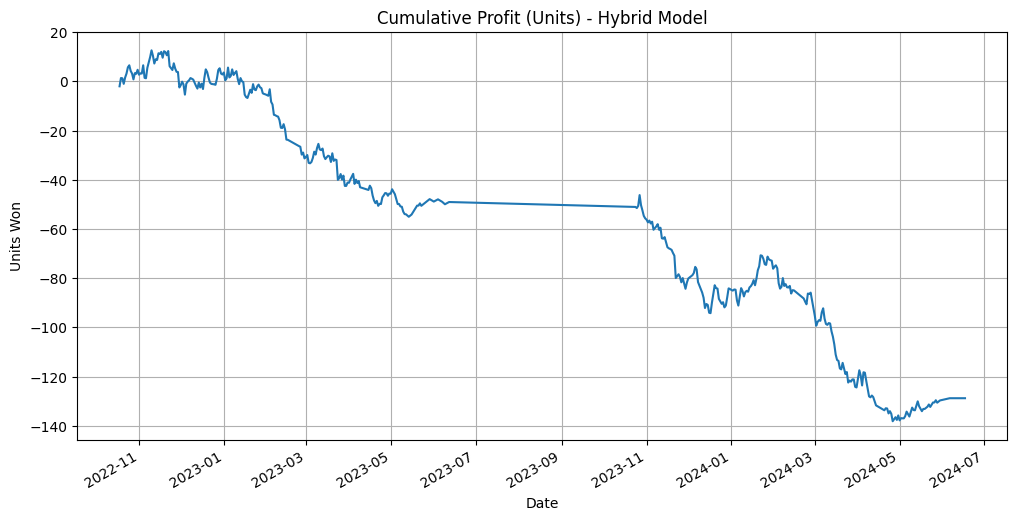

,gameId,gameDate,teamId_home,home_abbr,points_home,pred_points_home,season_end,teamId_away,away_abbr_x,points_away,pred_points_away,status,home_team,home_team_loc,home_team_rank,away_team,away_team_loc,away_abbr_y,away_team_rank,home_score,away_score,home_spread_betmgm,home_spread_fanduel,home_spread_caesars,home_spread_bet365,...,total_draftkings,total_bet_rivers_ny,over_odds_betmgm,over_odds_fanduel,over_odds_caesars,over_odds_bet365,over_odds_draftkings,over_odds_bet_rivers_ny,under_odds_betmgm,under_odds_fanduel,under_odds_caesars,under_odds_bet365,under_odds_draftkings,under_odds_bet_rivers_ny,SEASON,derived_game_id,pred_margin,actual_margin,market_margin,bet_home,bet_away,home_cover_result,away_cover_result,pnl,date_str
2621,22301087,2024-04-01,1610612766,CHA,104,115.875679,2024,1610612738,BOS,118,108.818092,Final,Charlotte Hornets,Charlotte,-1,Boston Celtics,Boston,BOS,-1,104,118,18.5,18.5,18.0,18.0,...,219.0,218.5,-115.0,-106.0,-110.0,-110.0,-110.0,-113,-105.0,-114.0,-110.0,-110.0,-110.0,-110,2023-24,2024-04-01_CHA_BOS,7.057587,-14,-18.5,True,False,1.0,-1.0,0.909,2024-04-01
2622,22301102,2024-04-03,1610612766,CHA,86,115.116493,2024,1610612757,POR,89,110.490654,Final,Charlotte Hornets,Charlotte,-1,Portland Trail Blazers,Portland,POR,-1,86,89,-1.5,-1.5,-1.5,-1.5,...,211.5,212.0,-105.0,-112.0,-110.0,-110.0,-118.0,-113,-115.0,-108.0,-110.0,-110.0,-102.0,-110,2023-24,2024-04-03_CHA_POR,4.625839,-3,1.5,True,False,-1.0,1.0,-1.000,2024-04-03
2623,22301115,2024-04-05,1610612766,CHA,124,117.841759,2024,1610612753,ORL,115,110.362579,Final,Charlotte Hornets,Charlotte,-1,Orlando Magic,Orlando,ORL,-1,124,115,12.5,12.5,13.0,12.5,...,207.0,206.5,-105.0,-108.0,-110.0,-110.0,-108.0,-112,-115.0,-112.0,-110.0,-110.0,-112.0,-112,2023-24,2024-04-05_CHA_ORL,7.479179,9,-12.0,True,False,1.0,-1.0,0.909,2024-04-05
2624,22301135,2024-04-07,1610612766,CHA,118,113.820946,2024,1610612760,OKC,121,108.892776,Final,Charlotte Hornets,Charlotte,-1,Oklahoma City Thunder,Oklahoma City,OKC,-1,118,121,7.5,7.5,7.5,7.5,...,218.0,218.5,-110.0,-110.0,-110.0,-110.0,-110.0,-112,-110.0,-110.0,-110.0,-110.0,-110.0,-112,2023-24,2024-04-07_CHA_OKC,4.928169,-3,-7.5,True,False,1.0,-1.0,0.909,2024-04-07
2625,22301144,2024-04-09,1610612766,CHA,104,119.081398,2024,1610612742,DAL,130,111.183151,Final,Charlotte Hornets,Charlotte,-1,Dallas Mavericks,Dallas,DAL,-1,104,130,12.5,12.5,12.5,12.5,...,224.5,223.5,-115.0,-112.0,-115.0,-110.0,-108.0,-113,-105.0,-108.0,-105.0,-110.0,-112.0,-110,2023-24,2024-04-09_CHA_DAL,7.898247,-26,-12.5,True,False,-1.0,1.0,-1.000,2024-04-09


In [82]:
# 1. Load Odds Data
odds_df = pd.read_sql("SELECT * FROM nba_odds", con=conn)

# 2. Clean Odds Data
# We need to standardize abbreviations to match our 'team_df' / 'dic_map'
# nba_odds has: 'BKN', 'CHA', 'PHI', etc.
# Our system uses: 'BKN', 'CHA', 'PHI', etc. (Mostly consistent)
# We need to map our predicted 'teamId' -> 'Abbreviation' to join.

# Create ID -> Abbr map from the original team_df
# Use the most recent abbreviation for each ID (e.g. NOK -> NOP)
id_to_abbr = team_df.sort_values('gameDate').groupby('teamId')['TEAM_ABBREVIATION'].last().to_dict()

def prepare_betting_data(predictions, odds, id_map):
    """
    Joins Model Predictions with Historical Odds.
    """
    # A. Aggregate Predictions to Game Level
    home_preds = predictions[predictions['isHome'] == 1].copy()
    away_preds = predictions[predictions['isHome'] == 0].copy()
    
    # Get Abbreviations
    home_preds['home_abbr'] = home_preds['teamId'].map(id_map)
    away_preds['away_abbr'] = away_preds['teamId'].map(id_map)
    
    # Merge Home/Away predictions
    game_preds = pd.merge(
        home_preds[['gameId', 'gameDate', 'teamId', 'home_abbr', 'points', 'pred_points', 'season_end']],
        away_preds[['gameId', 'teamId', 'away_abbr', 'points', 'pred_points']],
        on='gameId', suffixes=('_home', '_away')
    )
    
    # B. Prepare Odds for Join
    # keys: GAME_DATE (string), home_team_abbr
    odds_clean = odds.copy()
    odds_clean['GAME_DATE'] = pd.to_datetime(odds_clean['GAME_DATE'])
    
    # Rename for easier join
    odds_clean = odds_clean.rename(columns={
        'GAME_DATE': 'gameDate',
        'home_team_abbr': 'home_abbr',
        'away_team_abbr': 'away_abbr'
    })
    
    # Handle known abbr mismatches if any (e.g. PHX vs PHO, GS vs GSW)
    # Check what 'nba_odds' uses vs what 'team_df' uses.
    # Assuming standard mapping for now.
    
    # C. Join Predictions + Odds
    # We join on Date and Home Team ID (via Abbr)
    # Note: 'gameDate' in predictions is datetime64[ns].
    
    full_df = pd.merge(
        game_preds,
        odds_clean,
        left_on=['gameDate', 'home_abbr'],
        right_on=['gameDate', 'home_abbr'],
        how='inner' # We only bet on games we have odds for
    )
    
    # D. Calculate Edges
    # Model Margin (Home - Away)
    full_df['pred_margin'] = full_df['pred_points_home'] - full_df['pred_points_away']
    full_df['actual_margin'] = full_df['points_home'] - full_df['points_away']
    
    # Market Spread (DraftKings)
    # Note: home_spread_draftkings usually is likes "-4.5" (Home favored) or "+3.0" (Home dog)
    # If Market is -4.5, they expect Home Margin to be +4.5.
    # So "Market Expectation" = -1 * home_spread_draftkings
    full_df['market_margin'] = -1 * full_df['home_spread_draftkings']
    
    return full_df

# Run Data Prep
betting_df = prepare_betting_data(final_predictions, odds_df, id_to_abbr)

# %%
# 3. Execute Betting Strategy
def run_backtest(df, threshold=1.5):
    """
    Places bets where |Pred_Margin - Market_Margin| > threshold.
    """
    df = df.copy()
    
    # Logic:
    # If Model says Home wins by 10, Market says Home wins by 5 (Spread -5).
    # We think Home is BETTER than market. We bet Home -5.
    # pred_margin (10) > market_margin (5) + threshold -> BET HOME
    
    # If Model says Home wins by 2, Market says Home wins by 8 (Spread -8).
    # We think Home is WORSE. We bet Away +8.
    # pred_margin (2) < market_margin (8) - threshold -> BET AWAY
    
    df['bet_home'] = df['pred_margin'] > (df['market_margin'] + threshold)
    df['bet_away'] = df['pred_margin'] < (df['market_margin'] - threshold)
    
    # Outcome
    # Bet Home (Spread -X): Win if Actual Margin > Market Margin (Coverage)
    # e.g. Spread -5 (Market expects +5). Actual +7. 7 > 5. Win.
    # Push handling: If Actual == Market, No Bet result (0).
    df['home_cover_result'] = np.sign(df['actual_margin'] - df['market_margin'])
    
    # Bet Away (Spread +X): Equivalent to betting AGAINST Home Cover
    df['away_cover_result'] = -1 * df['home_cover_result']
    
    # PnL
    # -110 odds implies 0.909 profit on win, -1.0 loss.
    # We assume flat -110 for simplicity.
    price = 0.909
    
    df['pnl'] = 0.0
    
    # Home Bets
    df.loc[df['bet_home'] & (df['home_cover_result'] == 1), 'pnl'] += price
    df.loc[df['bet_home'] & (df['home_cover_result'] == -1), 'pnl'] -= 1.0
    
    # Away Bets
    df.loc[df['bet_away'] & (df['away_cover_result'] == 1), 'pnl'] += price
    df.loc[df['bet_away'] & (df['away_cover_result'] == -1), 'pnl'] -= 1.0
    
    return df

results = run_backtest(betting_df, threshold=2.0)

print(f"Bets Placed: {results['bet_home'].sum() + results['bet_away'].sum()}")
print(f"Total Profit (Units): {results['pnl'].sum():.2f}")
print(f"ROI: {(results['pnl'].sum() / (results['bet_home'].sum() + results['bet_away'].sum())) * 100:.2f}%")

# Visualize Cumulative Profit
results['date_str'] = results['gameDate'].dt.date
daily_pnl = results.groupby('gameDate')['pnl'].sum().cumsum()

plt.figure(figsize=(12, 6))
daily_pnl.plot(title='Cumulative Profit (Units) - Hybrid Model')
plt.xlabel('Date')
plt.ylabel('Units Won')
plt.grid(True)
plt.show()

# %%
results.tail()

In [72]:
nba_odds = pd.read_sql("SELECT * FROM nba_odds", conn)

display(nba_odds.isnull().sum())

GAME_DATE                      0
status                         0
home_team                      0
home_team_loc                  0
home_team_abbr                 0
                            ... 
under_odds_bet365           5379
under_odds_draftkings       5383
under_odds_bet_rivers_ny    8797
SEASON                         0
derived_game_id             6434
Length: 68, dtype: int64

In [79]:
nba_odds[['GAME_DATE', 'status', 'home_team', 'home_team_loc', 'home_team_abbr',
       'home_team_rank', 'away_team', 'away_team_loc', 'away_team_abbr',
       'away_team_rank', 'home_score', 'away_score', 
#        'home_spread_fanduel',
#  'home_spread_odds_fanduel',
#  'away_spread_fanduel',
#  'away_spread_odds_fanduel',
#  'home_ml_fanduel',
#  'away_ml_fanduel',
#  'total_fanduel',
#  'over_odds_fanduel',
#  'under_odds_fanduel',
 'home_spread_draftkings',
 'home_spread_odds_draftkings',
 'away_spread_draftkings',
 'away_spread_odds_draftkings',
 'home_ml_draftkings',
 'away_ml_draftkings',
 'total_draftkings',
 'over_odds_draftkings',
 'under_odds_draftkings',
        'SEASON']]

,GAME_DATE,status,home_team,home_team_loc,home_team_abbr,home_team_rank,away_team,away_team_loc,away_team_abbr,away_team_rank,home_score,away_score,home_spread_draftkings,home_spread_odds_draftkings,away_spread_draftkings,away_spread_odds_draftkings,home_ml_draftkings,away_ml_draftkings,total_draftkings,over_odds_draftkings,under_odds_draftkings,SEASON
0,2019-12-08,Final,Brooklyn Nets,Brooklyn,BKN,-1,Denver Nuggets,Denver,DEN,-1,105,102,4.5,-110.0,-4.5,-110.0,160.0,-190.0,212.5,-108.0,-113.0,2019-20
1,2019-12-08,Final,Charlotte Hornets,Charlotte,CHA,-1,Atlanta Hawks,Atlanta,ATL,-1,107,122,-2.0,-108.0,2.0,-112.0,-125.0,105.0,223.0,-112.0,-109.0,2019-20
2,2019-12-08,Final,Philadelphia 76ers,Philadelphia,PHI,-1,Toronto Raptors,Toronto,TOR,-1,110,104,-3.0,-112.0,3.0,-109.0,-152.0,128.0,213.5,-112.0,-109.0,2019-20
3,2019-12-08,Final,Washington Wizards,Washington,WAS,-1,Los Angeles Clippers,L.A. Clippers,LAC,-1,119,135,9.0,-110.0,-9.0,-110.0,370.0,-500.0,236.0,-108.0,-113.0,2019-20
4,2019-12-08,Final 5OT,Miami Heat,Miami,MIA,-1,Chicago Bulls,Chicago,CHI,-1,110,105,-6.5,-110.0,6.5,-110.0,-250.0,205.0,211.5,-112.0,-109.0,2019-20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13452,2017-10-30,Final,New Orleans Pelicans,New Orleans,NO,-1,Orlando Magic,Orlando,ORL,-1,99,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-18
13453,2017-10-30,Final,Memphis Grizzlies,Memphis,MEM,-1,Charlotte Hornets,Charlotte,CHA,-1,99,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-18
13454,2017-10-30,Final,Utah Jazz,Utah,UTA,-1,Dallas Mavericks,Dallas,DAL,-1,104,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-18
13455,2017-10-30,Final,Portland Trail Blazers,Portland,POR,-1,Toronto Raptors,Toronto,TOR,-1,85,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-18


In [78]:
nba_odds['GAME_DATE'].max()

'2026-01-01'